# Tutorial 14_B



In [1]:
import re, random
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
import matplotlib.pyplot as plt

torch.manual_seed(42)
random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cpu


# Part A: English → Urdu translation

## 1. Our own dataset (English, Urdu pairs)

In [2]:
pairs = [
    ("hello how are you", "ہیلو آپ کیسے ہیں"),
    ("i am fine thank you", "میں ٹھیک ہوں شکریہ"),
    ("what is your name", "آپ کا نام کیا ہے"),
    ("my name is irsa", "میرا نام عرسہ ہے"),
    ("i love programming", "مجھے پروگرامنگ پسند ہے"),
    ("i live in swabi", "میں صوابی میں رہتی ہوں"),
    ("where do you live", "آپ کہاں رہتے ہیں"),
    ("i am a student", "میں ایک طالب علم ہوں"),
    ("good morning", "صبح بخیر"),
    ("good night", "شب بخیر"),
    ("thank you", "شکریہ"),
    ("how old are you", "آپ کی عمر کتنی ہے"),
    ("i like tea", "مجھے چائے پسند ہے"),
    ("i like books", "مجھے کتابیں پسند ہیں"),
    ("she is my friend", "وہ میری دوست ہے"),
    ("he is my brother", "وہ میرا بھائی ہے"),
    ("this is my house", "یہ میرا گھر ہے"),
    ("i am hungry", "مجھے بھوک لگی ہے"),
    ("i am thirsty", "مجھے پیاس لگی ہے"),
    ("what are you doing", "آپ کیا کر رہے ہیں"),
    ("i love my country", "مجھے اپنے ملک سے محبت ہے"),
    ("i love pakistan", "مجھے پاکستان سے محبت ہے"),
    ("where is the school", "اسکول کہاں ہے"),
    ("i go to school", "میں اسکول جاتا ہوں"),
    ("i read a book", "میں کتاب پڑھتا ہوں"),
    ("the weather is good", "موسم اچھا ہے"),
    ("please help me", "برائے مہربانی میری مدد کریں"),
    ("see you tomorrow", "کل ملتے ہیں"),
    ("i drink water", "میں پانی پیتا ہوں"),
    ("this is a book", "یہ ایک کتاب ہے"),
    ("i am happy", "میں خوش ہوں"),
]
print("Number of pairs:", len(pairs))

Number of pairs: 31


## 2. Tokenize, build vocabularies, pad

In [3]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3

def clean(s):
    # remove punctuation (English and Urdu) and lowercase
    return re.sub(r"[؟۔!?.,،]", "", s.lower()).strip()

en_sents = [clean(e) for e, u in pairs]
ur_sents = [clean(u) for e, u in pairs]

def build_vocab(sentences):
    w2i = {"<pad>": PAD, "<sos>": SOS, "<eos>": EOS, "<unk>": UNK}
    for s in sentences:
        for w in s.split():
            if w not in w2i:
                w2i[w] = len(w2i)
    i2w = {i: w for w, i in w2i.items()}
    return w2i, i2w

en_w2i, en_i2w = build_vocab(en_sents)
ur_w2i, ur_i2w = build_vocab(ur_sents)
print("English vocab size:", len(en_w2i))
print("Urdu vocab size:", len(ur_w2i))

src_ids = [[en_w2i[w] for w in s.split()] for s in en_sents]
tgt_ids = [[ur_w2i[w] for w in s.split()] for s in ur_sents]

# Encoder input, decoder input (<sos> + target), decoder target (target + <eos>)
src = pad_sequence([torch.tensor(s) for s in src_ids], batch_first=True, padding_value=PAD)
dec_in = pad_sequence([torch.tensor([SOS] + t) for t in tgt_ids], batch_first=True, padding_value=PAD)
dec_out = pad_sequence([torch.tensor(t + [EOS]) for t in tgt_ids], batch_first=True, padding_value=PAD)
src_lengths = torch.tensor([len(s) for s in src_ids])   # stays on CPU (needed by pack_padded_sequence)
max_tgt_len = dec_out.shape[1]
print("src:", src.shape, "dec_in:", dec_in.shape, "dec_out:", dec_out.shape)

English vocab size: 60
Urdu vocab size: 67
src: torch.Size([31, 5]) dec_in: torch.Size([31, 7]) dec_out: torch.Size([31, 7])


## 3. Encoder-decoder RNN model

In [4]:
class Seq2Seq(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, emb_dim=64, hidden_units=128):
        super().__init__()
        self.enc_emb = nn.Embedding(src_vocab, emb_dim, padding_idx=PAD)
        self.encoder = nn.RNN(emb_dim, hidden_units, batch_first=True)
        self.dec_emb = nn.Embedding(tgt_vocab, emb_dim, padding_idx=PAD)
        self.decoder = nn.RNN(emb_dim, hidden_units, batch_first=True)
        self.fc = nn.Linear(hidden_units, tgt_vocab)

    def encode(self, src, lengths):
        packed = pack_padded_sequence(self.enc_emb(src), lengths, batch_first=True, enforce_sorted=False)
        _, h = self.encoder(packed)          # final hidden state = summary of the English sentence
        return h

    def forward(self, src, lengths, dec_in):
        h = self.encode(src, lengths)        # encoder state initializes the decoder (like initial_state=state_h)
        out, _ = self.decoder(self.dec_emb(dec_in), h)
        return self.fc(out)                  # (batch, tgt_len, tgt_vocab)

## 4. Train

Epoch 50/300 - loss: 0.0044
Epoch 100/300 - loss: 0.0017
Epoch 150/300 - loss: 0.0011
Epoch 200/300 - loss: 0.0008
Epoch 250/300 - loss: 0.0006
Epoch 300/300 - loss: 0.0005


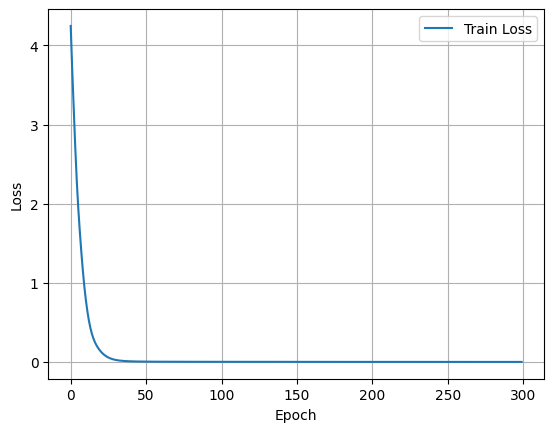

In [5]:
def train_seq2seq(hidden_units=128, epochs=300, lr=0.005, emb_dim=64, verbose=True):
    model = Seq2Seq(len(en_w2i), len(ur_w2i), emb_dim, hidden_units).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = model(src.to(device), src_lengths, dec_in.to(device))
        loss = criterion(logits.view(-1, len(ur_w2i)), dec_out.to(device).view(-1))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if verbose and (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch+1}/{epochs} - loss: {loss.item():.4f}")
    return model, losses

model, losses = train_seq2seq()
plt.plot(losses, label="Train Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.grid(True); plt.show()

## 5. Generate translations

In [7]:
def translate(model, sentence):
    model.eval()
    ids = [en_w2i.get(w, UNK) for w in clean(sentence).split()]
    with torch.no_grad():
        h = model.encode(torch.tensor([ids]).to(device), torch.tensor([len(ids)]))
        token = torch.tensor([[SOS]]).to(device)
        words = []
        for _ in range(max_tgt_len + 2):
            out, h = model.decoder(model.dec_emb(token), h)
            nxt = model.fc(out[:, -1]).argmax(-1)       # greedy decoding
            if nxt.item() == EOS:
                break
            words.append(ur_i2w[nxt.item()])
            token = nxt.unsqueeze(1)
    return " ".join(words)

for s in ["what is your name", "i love programming", "i live in swabi",
          "i love books", "my name is ali", "i am a student"]:
    print(f"{s:25s} -> {translate(model, s)}")

what is your name         -> آپ کا نام کیا ہے
i love programming        -> مجھے پروگرامنگ پسند ہے
i live in swabi           -> میں صوابی میں رہتی ہوں
i love books              -> مجھے پروگرامنگ پسند ہے
my name is ali            -> میرا نام عرسہ ہے
i am a student            -> میں ایک طالب علم ہوں


# Part B: Change the number of units, epochs and learning rate

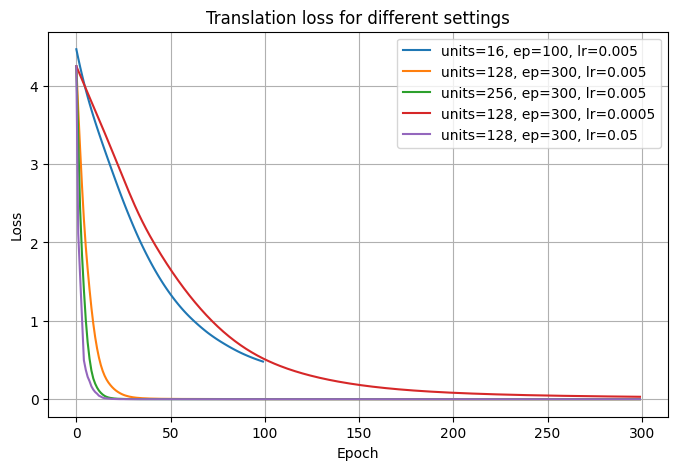

 units  epochs       lr  final loss  exact match  translation of 'what is your name'
    16     100    0.005      0.4801         0.74  آپ کا نام کیا ہے
   128     300    0.005      0.0005         1.00  آپ کا نام کیا ہے
   256     300    0.005      0.0001         1.00  آپ کا نام کیا ہے
   128     300   0.0005      0.0312         1.00  آپ کا نام کیا ہے
   128     300     0.05      0.0000         1.00  آپ کا نام کیا ہے


In [8]:
def exact_match(model):
    ok = sum(translate(model, e) == u for e, u in zip(en_sents, ur_sents))
    return ok / len(pairs)

configs = [
    {"hidden_units": 16,  "epochs": 100, "lr": 0.005},
    {"hidden_units": 128, "epochs": 300, "lr": 0.005},
    {"hidden_units": 256, "epochs": 300, "lr": 0.005},
    {"hidden_units": 128, "epochs": 300, "lr": 0.0005},
    {"hidden_units": 128, "epochs": 300, "lr": 0.05},
]

rows = []
plt.figure(figsize=(8, 5))
for cfg in configs:
    torch.manual_seed(42)
    m, l = train_seq2seq(**cfg, verbose=False)
    rows.append((cfg, l[-1], exact_match(m), translate(m, "what is your name")))
    plt.plot(l, label=f"units={cfg['hidden_units']}, ep={cfg['epochs']}, lr={cfg['lr']}")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Translation loss for different settings")
plt.legend(); plt.grid(True); plt.show()

print(f"{'units':>6} {'epochs':>7} {'lr':>8} {'final loss':>11} {'exact match':>12}  translation of 'what is your name'")
for cfg, loss, acc, tr in rows:
    print(f"{cfg['hidden_units']:>6} {cfg['epochs']:>7} {cfg['lr']:>8} {loss:>11.4f} {acc:>12.2f}  {tr}")

# Part C: One-to-many RNN for baby name generation


In [9]:
# Our own baby names dataset (girls and boys)
names = [
    "irsa", "aisha", "fatima", "zainab", "maryam", "hira", "sana", "ayesha", "noor", "laiba",
    "areeba", "hoor", "iqra", "amna", "khadija", "sara", "mahnoor", "eman", "rida", "anaya",
    "aliza", "inaya", "mehwish", "saba", "nimra", "rabia", "sidra", "farah", "hania", "zara",
    "ali", "ahmed", "hamza", "usman", "bilal", "hassan", "hussain", "omar", "umar", "zain",
    "faizan", "talha", "saad", "yusuf", "ibrahim", "ismail", "imran", "kamran", "fahad", "danish",
    "daniyal", "arslan", "adnan", "junaid", "shahid", "waqas", "zubair", "rehan", "ayaan", "rayyan",
]
names = sorted(set(n.lower() for n in names))
print("Number of names:", len(names))

N_PAD, N_START, N_END = 0, 1, 2
chars = sorted(set("".join(names)))
c2i = {c: i + 3 for i, c in enumerate(chars)}
i2c = {i: c for c, i in c2i.items()}
n_vocab = len(c2i) + 3

# input: <start> + name   |   target: name + <end>
name_in = pad_sequence([torch.tensor([N_START] + [c2i[c] for c in n]) for n in names],
                       batch_first=True, padding_value=N_PAD)
name_out = pad_sequence([torch.tensor([c2i[c] for c in n] + [N_END]) for n in names],
                        batch_first=True, padding_value=N_PAD)
print("Characters:", "".join(chars), "| input shape:", name_in.shape)

Number of names: 60
Characters: abdefhijklmnoqrstuwyz | input shape: torch.Size([60, 8])


Epoch 50/300 - loss: 0.7895
Epoch 100/300 - loss: 0.6758
Epoch 150/300 - loss: 0.6704
Epoch 200/300 - loss: 0.6686
Epoch 250/300 - loss: 0.6677
Epoch 300/300 - loss: 0.6672


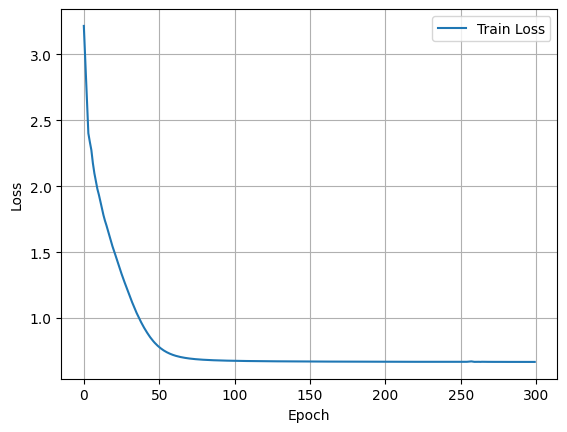

In [10]:
class NameRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=32, hidden_units=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=N_PAD)
        self.rnn = nn.RNN(emb_dim, hidden_units, batch_first=True)
        self.fc = nn.Linear(hidden_units, vocab_size)

    def forward(self, x, h=None):
        out, h = self.rnn(self.embedding(x), h)
        return self.fc(out), h

def train_names(hidden_units=128, epochs=300, lr=0.005, verbose=True):
    model = NameRNN(n_vocab, 32, hidden_units).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=N_PAD)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits, _ = model(name_in.to(device))
        loss = criterion(logits.view(-1, n_vocab), name_out.to(device).view(-1))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if verbose and (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch+1}/{epochs} - loss: {loss.item():.4f}")
    return model, losses

torch.manual_seed(42)
name_model, name_losses = train_names()
plt.plot(name_losses, label="Train Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.grid(True); plt.show()

## Generate new baby names

In [11]:
def generate_name(model, first_letter="", temperature=0.8, max_len=12):
    model.eval()
    with torch.no_grad():
        x = torch.tensor([[N_START]]).to(device)
        logits, h = model(x)                         # one input ...
        result = ""
        if first_letter:                             # optionally force the first letter
            result = first_letter.lower()
            x = torch.tensor([[c2i[result]]]).to(device)
            logits, h = model(x, h)
        for _ in range(max_len):                     # ... many outputs
            probs = torch.softmax(logits[0, -1] / temperature, dim=-1)
            idx = torch.multinomial(probs, 1).item()
            if idx == N_END:
                break
            if idx in i2c:
                result += i2c[idx]
            x = torch.tensor([[idx]]).to(device)
            logits, h = model(x, h)
    return result.capitalize()

print("Random names:")
for _ in range(10):
    n = generate_name(name_model)
    print(f"  {n:12s} {'(already in dataset)' if n.lower() in names else '(new!)'}")

print("\nNames starting with a chosen letter:")
for letter in ["a", "m", "z", "h"]:
    print(f"  {letter.upper()}: ", [generate_name(name_model, letter) for _ in range(4)])

Random names:
  Sidra        (already in dataset)
  Rabia        (already in dataset)
  Ayaan        (already in dataset)
  Nimra        (already in dataset)
  Sara         (already in dataset)
  Sana         (already in dataset)
  Eman         (already in dataset)
  Rabia        (already in dataset)
  Daniyal      (already in dataset)
  Sidra        (already in dataset)

Names starting with a chosen letter:
  A:  ['Areeba', 'Ali', 'Aisha', 'Aliza']
  M:  ['Mehwish', 'Maryam', 'Maryam', 'Mehwish']
  Z:  ['Zainab', 'Zainab', 'Zain', 'Zain']
  H:  ['Hamza', 'Hira', 'Hania', 'Hussain']


## Change units, epochs and learning rate for the name generator

{'hidden_units': 16, 'epochs': 100, 'lr': 0.005} -> final loss 1.552
    ['Imre', 'Farah', 'Arab', 'Aina', 'Hani', 'Aniqan']
{'hidden_units': 128, 'epochs': 300, 'lr': 0.005} -> final loss 0.667
    ['Sidra', 'Rabia', 'Ayaan', 'Nimra', 'Sara', 'Sana']
{'hidden_units': 256, 'epochs': 500, 'lr': 0.005} -> final loss 0.666
    ['Bilal', 'Eman', 'Daniyal', 'Sara', 'Fatima', 'Sara']
{'hidden_units': 128, 'epochs': 300, 'lr': 0.0005} -> final loss 0.830
    ['Smer', 'Zuna', 'Foor', 'Nimra', 'Maryam', 'Saan']


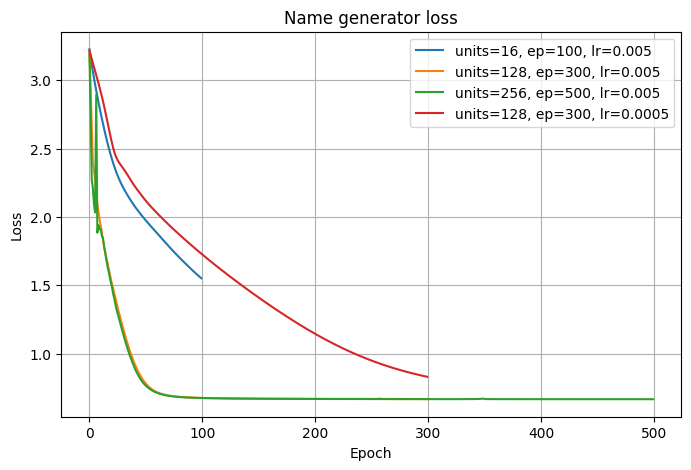

In [12]:
name_configs = [
    {"hidden_units": 16,  "epochs": 100, "lr": 0.005},
    {"hidden_units": 128, "epochs": 300, "lr": 0.005},
    {"hidden_units": 256, "epochs": 500, "lr": 0.005},
    {"hidden_units": 128, "epochs": 300, "lr": 0.0005},
]

plt.figure(figsize=(8, 5))
for cfg in name_configs:
    torch.manual_seed(42)
    m, l = train_names(**cfg, verbose=False)
    plt.plot(l, label=f"units={cfg['hidden_units']}, ep={cfg['epochs']}, lr={cfg['lr']}")
    print(cfg, f"-> final loss {l[-1]:.3f}")
    print("   ", [generate_name(m) for _ in range(6)])
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Name generator loss")
plt.legend(); plt.grid(True); plt.show()